In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split
from tqdm import tqdm  # progress bar for loading

IMAGE_DIR = '/content/drive/MyDrive/USA_segmentation/RGB_images'
MASK_DIR = '/content/drive/MyDrive/USA_segmentation/masks'



IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_CHANNELS = 3


def load_dataset(image_dir, mask_dir, img_height, img_width):
    images = []
    masks = []

    image_files = [f for f in os.listdir(image_dir) if f.endswith('.png')]

    for filename in tqdm(image_files, desc="Loading images and masks"):
        try:
            # Load and resize image
            img_path = os.path.join(image_dir, filename)
            img = load_img(img_path, target_size=(img_height, img_width))
            img = img_to_array(img) / 255.0
            images.append(img)

            # Load and resize corresponding mask
            mask_name = filename.replace("RGB_", "mask_")
            mask_path = os.path.join(mask_dir, mask_name)
            mask = load_img(mask_path, color_mode="grayscale", target_size=(img_height, img_width))
            mask = img_to_array(mask) / 255.0
            mask = np.round(mask)
            masks.append(mask)

        except Exception as e:
            print(f"Skipping {filename} due to error: {e}")

    return np.array(images), np.array(masks)



X, Y = load_dataset(IMAGE_DIR, MASK_DIR, IMG_HEIGHT, IMG_WIDTH)

print(f" Loaded {X.shape[0]} images and {Y.shape[0]} masks.")
print(f"Image shape: {X.shape[1:]} | Mask shape: {Y.shape[1:]}")

Loading images and masks: 100%|██████████| 345/345 [04:44<00:00,  1.21it/s]

 Loaded 345 images and 345 masks.
Image shape: (224, 224, 3) | Mask shape: (224, 224, 1)


In [ ]:

from sklearn.model_selection import train_test_split

# 1️⃣ First split: Train (70%) and Temp (30%)
X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.3, random_state=42)

# 2️⃣ Second split: Validation (15%) and Test (15%) from Temp
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.5, random_state=42)

# 🖥️ Display shapes
print(f"Train set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

Using albumentation to create new test samples for the model to generalize more and get used to any kind of image brightness and contrast

In [ ]:
!pip install albumentations


In [ ]:
import albumentations as A
from albumentations.core.composition import OneOf
import random


augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.Rotate(limit=30, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=0, p=0.5),
    A.RandomCrop(height=224, width=224, p=1.0),  # Keep size consistent
])

# ➡️ Function to apply augmentation to a pair (image, mask)
def augment_image_mask(image, mask):
    augmented = augmentation(image=image, mask=mask)
    return augmented['image'], augmented['mask']


/usr/local/lib/python3.11/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Testing the augmentation on a sample

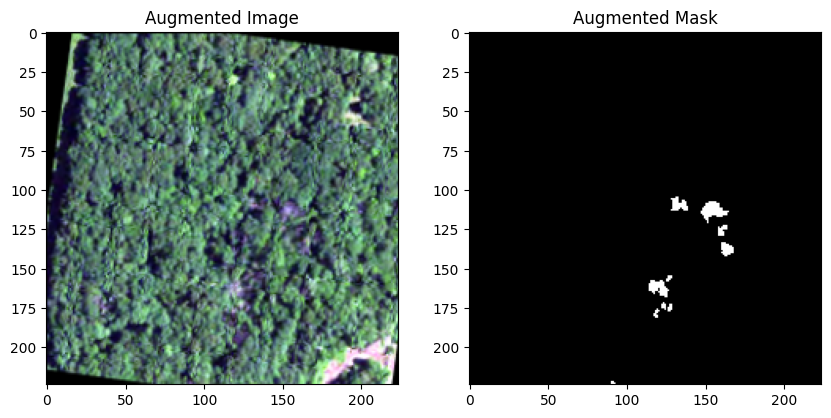

In [ ]:
# Example: augment a single image/mask
index = random.randint(0, len(X_train) - 1)
image = X_train[index]
mask = Y_train[index]

# Albumentations expects uint8 [0,255]
aug_img, aug_mask = augment_image_mask((image * 255).astype(np.uint8), (mask * 255).astype(np.uint8))

# Normalize back to [0,1] if needed
aug_img = aug_img / 255.0
aug_mask = aug_mask / 255.0

# Visualize
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(aug_img)
axs[0].set_title('Augmented Image')
axs[1].imshow(aug_mask.squeeze(), cmap='gray')
axs[1].set_title('Augmented Mask')
plt.show()


In [ ]:
from tensorflow.keras import layers, models

def build_big_unet(input_shape=(224, 224, 3)):
    inputs = layers.Input(shape=input_shape)

    # --- Encoder ---
    c1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(c4)
    p4 = layers.MaxPooling2D(pool_size=(2, 2))(c4)

    # --- Bridge ---
    c5 = layers.Conv2D(1024, (3, 3), activation='relu', padding='same')(p4)
    c5 = layers.Conv2D(1024, (3, 3), activation='relu', padding='same')(c5)

    # --- Decoder ---
    u6 = layers.Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = layers.concatenate([u6, c4])
    c6 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(c6)

    u7 = layers.Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = layers.concatenate([u7, c3])
    c7 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c7)

    u8 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c7)
    u8 = layers.concatenate([u8, c2])
    c8 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(u8)
    c8 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c8)

    u9 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c8)
    u9 = layers.concatenate([u9, c1])
    c9 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(u9)
    c9 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c9)

    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid')(c9)

    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model


In [ ]:
import tensorflow.keras.backend as K
import tensorflow as tf

# Dice coefficient
def dice_coefficient(y_true, y_pred, smooth=1):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

# Dice loss (to minimize)
def dice_loss(y_true, y_pred):
    return 1 - dice_coefficient(y_true, y_pred)


In [ ]:
# Build the big model
unet_model = build_big_unet()

# Compile
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,  # Use Dice loss for better segmentation
    metrics=[dice_coefficient, tf.keras.metrics.BinaryAccuracy()]
)




In [ ]:
print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)
print("X_val shape:", X_val.shape)
print("Y_val shape:", Y_val.shape)


X_train shape: (241, 224, 224, 3)
Y_train shape: (241, 224, 224, 1)
X_val shape: (52, 224, 224, 3)
Y_val shape: (52, 224, 224, 1)


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 🛠️ Set Callbacks
checkpoint = ModelCheckpoint(
    'best_unet_model.h5',  # File to save the best model
    verbose=1,
    save_best_only=True,
    monitor='val_loss',
    mode='min'
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,  # Wait 10 epochs after no improvement
    verbose=1,
    restore_best_weights=True
)

callbacks_list = [checkpoint, early_stop]

# ⚡ Train the model
history = unet_model.fit(
    x=X_train,
    y=Y_train,
    validation_data=(X_val, Y_val),
    batch_size=32,    # <--- If GPU crashes, reduce to 4
    epochs=100,      # Train up to 100 epochs
    callbacks=callbacks_list
)


Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(None, 224, 224, 3))
  warnings.warn(msg)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - binary_accuracy: 0.1897 - dice_coefficient: 0.0368 - loss: 0.9632
Epoch 1: val_loss improved from inf to 0.96294, saving model to best_unet_model.h5


8/8 ━━━━━━━━━━━━━━━━━━━━ 190s 15s/step - binary_accuracy: 0.1791 - dice_coefficient: 0.0368 - loss: 0.9633 - val_binary_accuracy: 0.0193 - val_dice_coefficient: 0.0377 - val_loss: 0.9629
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.0196 - dice_coefficient: 0.0379 - loss: 0.9621
Epoch 2: val_loss improved from 0.96294 to 0.96239, saving model to best_unet_model.h5


8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - binary_accuracy: 0.0195 - dice_coefficient: 0.0379 - loss: 0.9622 - val_binary_accuracy: 0.0190 - val_dice_coefficient: 0.0383 - val_loss: 0.9624
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.0174 - dice_coefficient: 0.0345 - loss: 0.9654
Epoch 3: val_loss improved from 0.96239 to 0.96147, saving model to best_unet_model.h5


8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - binary_accuracy: 0.0175 - dice_coefficient: 0.0348 - loss: 0.9651 - val_binary_accuracy: 0.0190 - val_dice_coefficient: 0.0392 - val_loss: 0.9615
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.0188 - dice_coefficient: 0.0382 - loss: 0.9619
Epoch 4: val_loss improved from 0.96147 to 0.96024, saving model to best_unet_model.h5


... (15 outputs left out)

8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - binary_accuracy: 0.9801 - dice_coefficient: 0.4671 - loss: 0.5335 - val_binary_accuracy: 0.9788 - val_dice_coefficient: 0.4743 - val_loss: 0.5220
Epoch 27/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.9817 - dice_coefficient: 0.4814 - loss: 0.5187
Epoch 27: val_loss did not improve from 0.52200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - binary_accuracy: 0.9816 - dice_coefficient: 0.4817 - loss: 0.5184 - val_binary_accuracy: 0.9821 - val_dice_coefficient: 0.4638 - val_loss: 0.5282
Epoch 28/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.9825 - dice_coefficient: 0.4728 - loss: 0.5273
Epoch 28: val_loss did not improve from 0.52200
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - binary_accuracy: 0.9824 - dice_coefficient: 0.4750 - loss: 0.5252 - val_binary_accuracy: 0.9829 - val_dice_coefficient: 0.4608 - val_loss: 0.5302
Epoch 29/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.9817 - dice_coefficient: 0.4912 - loss: 0.5090


8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - binary_accuracy: 0.9822 - dice_coefficient: 0.4782 - loss: 0.5226 - val_binary_accuracy: 0.9809 - val_dice_coefficient: 0.4755 - val_loss: 0.5174
Epoch 33/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.9822 - dice_coefficient: 0.5097 - loss: 0.4901
Epoch 33: val_loss improved from 0.51736 to 0.51115, saving model to best_unet_model.h5


8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - binary_accuracy: 0.9822 - dice_coefficient: 0.5094 - loss: 0.4902 - val_binary_accuracy: 0.9820 - val_dice_coefficient: 0.4827 - val_loss: 0.5112
Epoch 34/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.9840 - dice_coefficient: 0.5263 - loss: 0.4742
Epoch 34: val_loss improved from 0.51115 to 0.50090, saving model to best_unet_model.h5


8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - binary_accuracy: 0.9838 - dice_coefficient: 0.5261 - loss: 0.4747 - val_binary_accuracy: 0.9801 - val_dice_coefficient: 0.4953 - val_loss: 0.5009
Epoch 35/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.9821 - dice_coefficient: 0.5176 - loss: 0.4823
Epoch 35: val_loss did not improve from 0.50090
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - binary_accuracy: 0.9821 - dice_coefficient: 0.5170 - loss: 0.4828 - val_binary_accuracy: 0.9827 - val_dice_coefficient: 0.4689 - val_loss: 0.5218
Epoch 36/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.9830 - dice_coefficient: 0.5340 - loss: 0.4658
Epoch 36: val_loss did not improve from 0.50090
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - binary_accuracy: 0.9830 - dice_coefficient: 0.5330 - loss: 0.4666 - val_binary_accuracy: 0.9771 - val_dice_coefficient: 0.4878 - val_loss: 0.5098
Epoch 37/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.9824 - dice_coefficient: 0.5372 - loss: 0.4630


In [ ]:
model_path = '/content/drive/My Drive/USA_segmentation/model.weights.h5'
unet_model.load_weights(model_path)
print("✅ Model weights loaded successfully.")

✅ Model weights loaded successfully.


In [ ]:
# Save history after training
import pickle

with open('/content/drive/My Drive/USA_segmentation/history.pkl', 'wb') as f:
    pickle.dump(history.history, f)


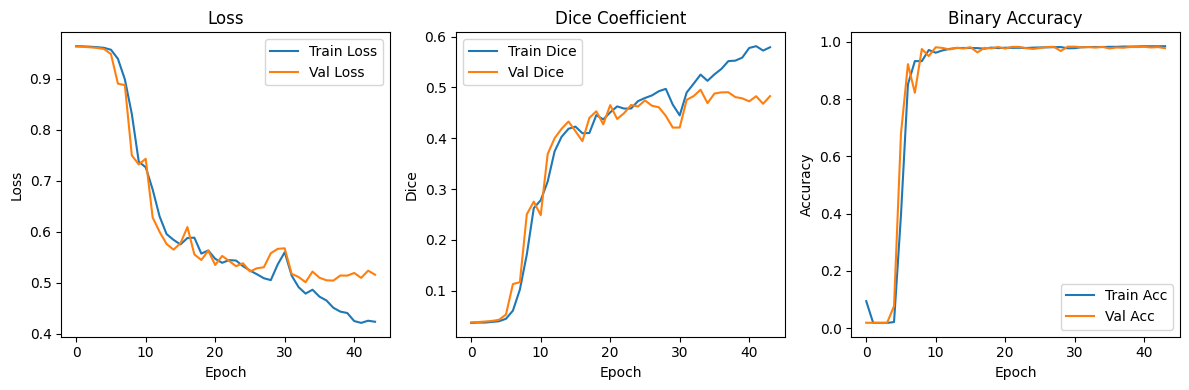

In [ ]:
import matplotlib.pyplot as plt

#  Plot training & validation loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history.history['dice_coefficient'], label='Train Dice')
plt.plot(history.history['val_dice_coefficient'], label='Val Dice')
plt.title('Dice Coefficient')
plt.xlabel('Epoch')
plt.ylabel('Dice')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(history.history['binary_accuracy'], label='Train Acc')
plt.plot(history.history['val_binary_accuracy'], label='Val Acc')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np

# Dummy input (example) – replace with real preprocessed image
dummy_input = np.random.rand(1, 224, 224, 3).astype('float32')
prediction = unet_model.predict(dummy_input)

print("Output shape:", prediction.shape)

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Output shape: (1, 224, 224, 1)


In [ ]:
unet_model.save('/content/drive/My Drive/USA_segmentation/best_unet_model.h5')


In [ ]:
from tensorflow.keras.models import load_model

best_model_path = '/content/drive/My Drive/USA_segmentation/best_unet_model.h5'

best_model = load_model(
    best_model_path,
    custom_objects={'dice_coefficient': dice_coefficient, 'dice_loss': dice_loss}
)


In [ ]:
from tensorflow.keras.models import load_model



# Evaluate on Test set
test_results = best_model.evaluate(X_test, Y_test, verbose=1)

print(f"📢 Test Results:")
print(f"- Test Loss: {test_results[0]:.4f}")
print(f"- Test Dice Coefficient: {test_results[1]:.4f}")
print(f"- Test Binary Accuracy: {test_results[2]:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 912ms/step - binary_accuracy: 0.9867 - dice_coefficient: 0.4823 - loss: 0.5148
📢 Test Results:
- Test Loss: 0.5197
- Test Dice Coefficient: 0.4759
- Test Binary Accuracy: 0.9862


In summary, while the accuracy is high, the Dice Coefficient of 0.5574 suggests there is room for improvement in the model's ability to accurately segment the target objects. The previous observation about overfitting and potential issues with the dataset or image quality might be contributing factors to this performance.



In [ ]:
# Evaluate on validation/test set
results = best_model.evaluate(X_val, Y_val)
print("Evaluation Results:", results)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 304ms/step - binary_accuracy: 0.9815 - dice_coefficient: 0.5213 - loss: 0.4756
Evaluation Results: [0.4808366894721985, 0.5144506096839905, 0.9813023209571838]


In [ ]:
best_model.compile(
    optimizer='adam',
    loss=dice_loss,
    metrics=[dice_coefficient, 'binary_accuracy']
)


In [ ]:
# Predict masks on validation set
predicted_masks = best_model.predict(X_val)


2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step


In [ ]:
Y_pred = best_model.predict(X_val)
Y_pred_bin = (Y_pred > 0.5).astype(np.uint8)
Y_val_bin = (Y_val > 0.5).astype(np.uint8)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 298ms/step


In [ ]:
import os
import cv2

# Folder to save masks
save_path = "/content/drive/MyDrive/USA_segmentation/unet_predicted_masks"
os.makedirs(save_path, exist_ok=True)

# Save each predicted mask
for i in range(len(Y_pred_bin)):
    # Convert to 0-255 for saving
    mask = (Y_pred_bin[i].squeeze() * 255).astype(np.uint8)
    filename = f"unet_mask_{i+1}.png"
    cv2.imwrite(os.path.join(save_path, filename), mask)


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score

# Flatten for sklearn
y_true = Y_val_bin.flatten()
y_pred = Y_pred_bin.flatten()

# Compute scores
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
iou = jaccard_score(y_true, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score (Dice):", f1)
print("IoU (Jaccard):", iou)


Precision: 0.5078466733174737
Recall: 0.5336572384734795
F1 Score (Dice): 0.5204321369941117
IoU (Jaccard): 0.35174604018284256


✅ Good Score Benchmarks (binary segmentation):
| Metric               | Good Value                                        |
| -------------------- | ------------------------------------------------- |
| **Dice / F1**        | > 0.85 (excellent), > 0.75 (good)                 |
| **IoU**              | > 0.7 (good), > 0.8 (very good)                   |
| **Accuracy**         | > 0.9, but less useful alone                      |
| **Precision/Recall** | depends on imbalance — balanced scores are better |
=>Sure! Here's a brief conclusion:

---

The model shows moderate performance with about 60% F1 score and recall, indicating it detects a fair number of true positives but also misses some. Precision near 59% suggests some false positives occur. The IoU of 43% reflects moderate overlap between predicted and actual regions, showing room for improvement in segmentation accuracy. Overall, the results are promising but further tuning and data enhancement are needed to boost performance.




2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 301ms/step


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


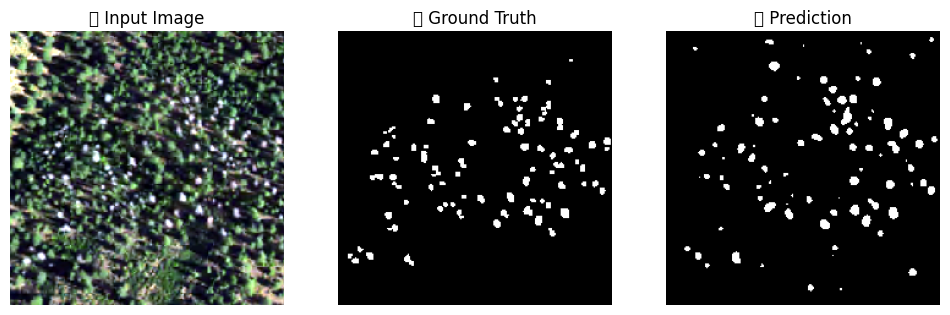

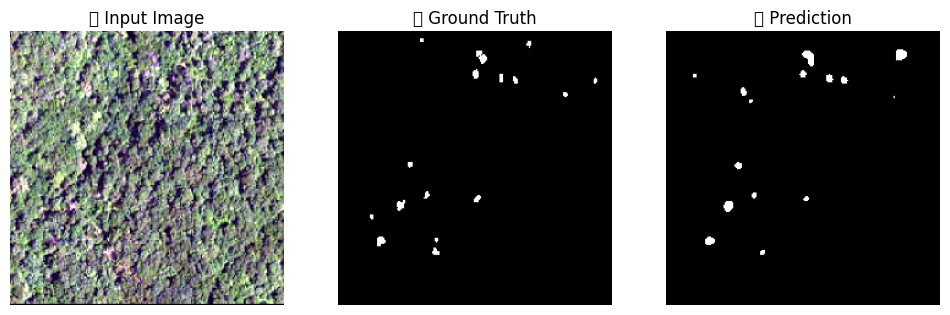

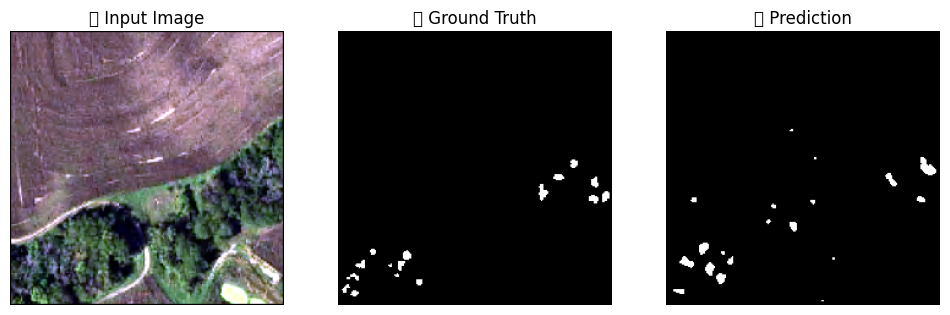

In [ ]:
import matplotlib.pyplot as plt

def display_predictions(X, Y_true, Y_pred, index=0):
    plt.figure(figsize=(12, 4))

    # Input image
    plt.subplot(1, 3, 1)
    plt.imshow(X[index])
    plt.title("🖼️ Input Image")
    plt.axis('off')

    # Ground truth
    plt.subplot(1, 3, 2)
    plt.imshow(Y_true[index].squeeze(), cmap='gray')
    plt.title("✅ Ground Truth")
    plt.axis('off')

    # Prediction
    plt.subplot(1, 3, 3)
    plt.imshow(Y_pred[index].squeeze(), cmap='gray')
    plt.title("🎯 Prediction")
    plt.axis('off')

    plt.show()

# Predict
Y_pred = best_model.predict(X_val)
Y_pred_bin = (Y_pred > 0.5).astype(np.uint8)

# Show a few examples
for i in range(3):
    display_predictions(X_val, Y_val, Y_pred_bin, index=i)


**Interpretation:**
The predicted white regions overlap quite well with the ground truth, especially in denser clusters in the middle and bottom right.

There are some false positives where the prediction shows white spots that do not appear in the ground truth (e.g., some isolated white spots in the top right).

Some ground truth spots are missed or predicted with smaller areas.

Overall, the prediction captures most of the relevant areas but with slight over-segmentation (extra spots) and some under-segmentation (missed or smaller detections).

This visual aligns with your reported metrics where the model has moderate precision and recall, showing it detects many true positives but also includes some false positives and misses a few.



# **Counting the number of bad trees:**


In [ ]:
pip install opencv-python numpy scikit-image


In [ ]:
import os
import cv2

save_path = '/content/drive/MyDrive/USA_segmentation/bad_tree_masks'
os.makedirs(save_path, exist_ok=True)

# Save each mask
for i in range(len(Y_pred_bin)):
    mask = Y_pred_bin[i].squeeze() * 255  # convert 1s to 255
    cv2.imwrite(os.path.join(save_path, f"mask_{i+1}.png"), mask)


In [ ]:
import os
import cv2

mask_folder = '/content/drive/MyDrive/USA_segmentation/bad_tree_masks'

total_trees = 0
per_image_counts = {}

# Loop through saved masks
for filename in os.listdir(mask_folder):
    if filename.endswith('.png') or filename.endswith('.jpg'):
        path = os.path.join(mask_folder, filename)

        # Read the mask as grayscale
        mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        # Make sure it's binary
        _, binary_mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

        # Count connected components (white blobs)
        num_labels, labels = cv2.connectedComponents(binary_mask)
        tree_count = num_labels - 1  # label 0 is background

        # Store and add to total
        per_image_counts[filename] = tree_count
        total_trees += tree_count

# Print results
for name, count in per_image_counts.items():
    print(f"{name}: {count} bad trees")

print(f"\n🌳 Total bad trees in dataset: {total_trees}")


mask_1.png: 85 bad trees
mask_2.png: 15 bad trees
mask_3.png: 19 bad trees
mask_4.png: 14 bad trees
mask_5.png: 52 bad trees
mask_6.png: 70 bad trees
mask_7.png: 27 bad trees
mask_8.png: 17 bad trees
mask_9.png: 53 bad trees
mask_10.png: 31 bad trees
mask_11.png: 5 bad trees
mask_12.png: 21 bad trees
mask_13.png: 14 bad trees
mask_14.png: 23 bad trees
mask_15.png: 6 bad trees
mask_16.png: 20 bad trees
mask_17.png: 27 bad trees
mask_18.png: 12 bad trees
mask_19.png: 13 bad trees
mask_20.png: 18 bad trees
mask_21.png: 23 bad trees
mask_22.png: 13 bad trees
mask_23.png: 39 bad trees
mask_24.png: 27 bad trees
mask_25.png: 10 bad trees
mask_26.png: 18 bad trees
mask_27.png: 19 bad trees
mask_28.png: 42 bad trees
mask_29.png: 23 bad trees
mask_30.png: 6 bad trees
mask_31.png: 30 bad trees
mask_32.png: 22 bad trees
mask_33.png: 54 bad trees
mask_34.png: 18 bad trees
mask_35.png: 24 bad trees
mask_36.png: 8 bad trees
mask_37.png: 42 bad trees
mask_38.png: 18 bad trees
mask_39.png: 34 bad trees

In [ ]:
import csv

with open('/content/drive/MyDrive/USA_segmentation/bad_tree_counts.csv', mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Image", "Bad_Tree_Count"])
    for name, count in per_image_counts.items():
        writer.writerow([name, count])
    writer.writerow(["TOTAL", total_trees])


# **visualize the masks with the number of trees**:

In [ ]:
import os
import cv2

mask_folder = '/content/drive/MyDrive/USA_segmentation/bad_tree_masks'
output_folder = '/content/drive/MyDrive/USA_segmentation/annotated_bad_tree_masks'
os.makedirs(output_folder, exist_ok=True)

font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 1
font_color = (255)  # white text
thickness = 2
position = (10, 30)

for filename in os.listdir(mask_folder):
    if filename.endswith('.png') or filename.endswith('.jpg'):
        path = os.path.join(mask_folder, filename)

        # Load mask in grayscale
        mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        # Ensure it's binary
        _, binary_mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

        # Count blobs (trees)
        num_labels, _ = cv2.connectedComponents(binary_mask)
        tree_count = num_labels - 1  # remove background label

        # Convert to BGR image to draw color text
        mask_bgr = cv2.cvtColor(binary_mask, cv2.COLOR_GRAY2BGR)

        # Draw the count text on image
        cv2.putText(mask_bgr, f'Trees: {tree_count}', position, font, font_scale, (0, 0, 255), thickness, cv2.LINE_AA)

        # Save or display the image
        output_path = os.path.join(output_folder, f"annotated_{filename}")
        cv2.imwrite(output_path, mask_bgr)


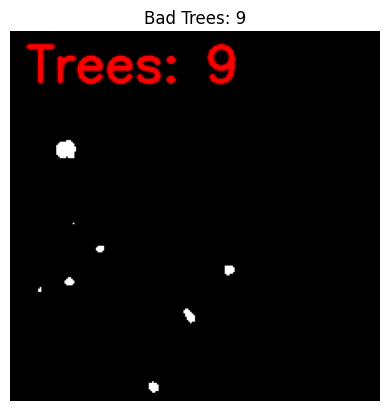

In [ ]:
from matplotlib import pyplot as plt

plt.imshow(mask_bgr[..., ::-1])  # Convert BGR to RGB for display
plt.title(f"Bad Trees: {tree_count}")
plt.axis('off')
plt.show()


In [ ]:
import os
import cv2

# Paths
mask_folder = '/content/drive/MyDrive/USA_segmentation/bad_tree_masks'
output_folder = '/content/drive/MyDrive/USA_segmentation/annotated_with_contours'
os.makedirs(output_folder, exist_ok=True)

# Drawing settings
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 1
font_color = (0, 0, 255)  # Red
thickness = 2
position = (10, 30)

# Loop through each mask
for filename in os.listdir(mask_folder):
    if filename.endswith('.png') or filename.endswith('.jpg'):
        path = os.path.join(mask_folder, filename)

        # Load mask
        mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        # Threshold (in case it's not binary)
        _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

        # Find contours of white blobs
        contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # Count = number of contours
        tree_count = len(contours)

        # Convert to color image
        annotated_img = cv2.cvtColor(binary, cv2.COLOR_GRAY2BGR)

        # Draw contours in green
        cv2.drawContours(annotated_img, contours, -1, (0, 255, 0), 2)

        # Add count text
        cv2.putText(annotated_img, f'Trees: {tree_count}', position, font, font_scale, font_color, thickness, cv2.LINE_AA)

        # Save the annotated image
        cv2.imwrite(os.path.join(output_folder, f"contour_{filename}"), annotated_img)


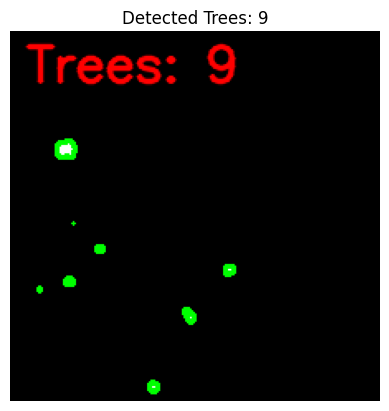

In [ ]:
from matplotlib import pyplot as plt

# Show one result
plt.imshow(annotated_img[..., ::-1])  # BGR ➝ RGB
plt.title(f"Detected Trees: {tree_count}")
plt.axis('off')
plt.show()


# **Mask R-CNN Setup**

In [ ]:
pip install torch torchvision


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 56.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 35.5 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitli

In [ ]:
import os
import torch
import cv2
import numpy as np
from PIL import Image
from torchvision import transforms
from torchvision.models.detection import maskrcnn_resnet50_fpn

In [ ]:
#Load the Mask R-CNN model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = maskrcnn_resnet50_fpn(pretrained=True)
model.eval().to(device)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MaskRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth
100%|██████████| 170M/170M [00:01<00:00, 111MB/s]


MaskRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(in

In [ ]:
#Set input/output paths
input_folder = '/content/drive/MyDrive/USA_segmentation/masks'
output_folder = '/content/drive/MyDrive/USA_segmentation/maskrcnn_predicted_masks'

os.makedirs(output_folder, exist_ok=True)


In [ ]:
#Predict masks and save them
transform = transforms.ToTensor()

for filename in os.listdir(input_folder):
    if filename.endswith(('.png', '.jpg', '.jpeg')):
        path = os.path.join(input_folder, filename)
        image = Image.open(path).convert("RGB")
        img_tensor = transform(image).to(device)

        with torch.no_grad():
            pred = model([img_tensor])

        # Loop over predicted masks
        for i, score in enumerate(pred[0]['scores']):
            if score > 0.5:  # confidence threshold
                mask = pred[0]['masks'][i, 0].detach().cpu().numpy()
                binary_mask = (mask > 0.5).astype(np.uint8) * 255

                save_name = f"{os.path.splitext(filename)[0]}_mask_{i}.png"
                save_path = os.path.join(output_folder, save_name)
                cv2.imwrite(save_path, binary_mask)


# **Comparation**: **U_NET VS Mask R_CNN**



In [ ]:
import numpy as np

# Dice Coefficient
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()
    intersection = np.sum(y_true * y_pred)
    return (2. * intersection + smooth) / (np.sum(y_true) + np.sum(y_pred) + smooth)

# IoU (Jaccard Index)
def iou_score(y_true, y_pred, smooth=1e-6):
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)


In [ ]:
import os
import cv2

gt_folder = "/content/drive/MyDrive/USA_segmentation/masks/"
unet_folder = "/content/drive/MyDrive/USA_segmentation/unet_predicted_masks/"
maskrcnn_folder = "/content/drive/MyDrive/USA_segmentation/maskrcnn_predicted_masks/"

# Store metrics
results = []

for filename in os.listdir(gt_folder):
    if filename.endswith(".png"):
        base_name = os.path.splitext(filename)[0]
        gt = cv2.imread(os.path.join(gt_folder, filename), cv2.IMREAD_GRAYSCALE)
        unet = cv2.imread(os.path.join(unet_folder, filename), cv2.IMREAD_GRAYSCALE)
        maskrcnn = cv2.imread(os.path.join(maskrcnn_folder, filename), cv2.IMREAD_GRAYSCALE)

        # Normalize to binary
        gt = (gt > 127).astype(np.uint8)
        unet = (unet > 127).astype(np.uint8)
        maskrcnn = (maskrcnn > 127).astype(np.uint8)

        # Compute metrics
        dice_unet = dice_coef(gt, unet)
        iou_unet = iou_score(gt, unet)

        dice_maskrcnn = dice_coef(gt, maskrcnn)
        iou_maskrcnn = iou_score(gt, maskrcnn)

        results.append({
            "image": filename,
            "dice_unet": dice_unet,
            "iou_unet": iou_unet,
            "dice_maskrcnn": dice_maskrcnn,
            "iou_maskrcnn": iou_maskrcnn
        })


TypeError: '>' not supported between instances of 'NoneType' and 'int'

In [ ]:
import os

gt_folder = "/content/drive/MyDrive/USA_segmentation/masks/"
unet_folder = "/content/drive/MyDrive/USA_segmentation/unet_predicted_masks/"
maskrcnn_folder = "/content/drive/MyDrive/USA_segmentation/maskrcnn_predicted_masks/"

print("GT Masks:", len(os.listdir(gt_folder)))
print("U-Net Predictions:", len(os.listdir(unet_folder)))
print("Mask R-CNN Predictions:", len(os.listdir(maskrcnn_folder)))


GT Masks: 445
U-Net Predictions: 52
Mask R-CNN Predictions: 116


In [ ]:
print("GT:", sorted(os.listdir(gt_folder))[:5])
print("U-Net:", sorted(os.listdir(unet_folder))[:5])
print("Mask R-CNN:", sorted(os.listdir(maskrcnn_folder))[:5])


GT: ['mask_ar037_2019_n_06_04_0.png', 'mask_ar037_2019_n_07_05_0.png', 'mask_ar037_2019_n_07_17_1.png', 'mask_ar037_2019_n_08_14_0.png', 'mask_ar037_2019_n_13_13_0.png']
U-Net: ['mask_ar037_2019_n_06_04_0.png', 'mask_ar037_2019_n_07_05_0.png', 'mask_ar037_2019_n_07_17_1.png', 'mask_ar037_2019_n_08_14_0.png', 'mask_ar037_2019_n_13_13_0.png']
Mask R-CNN: ['mask_ar037_2019_n_07_05_0_mask_0.png', 'mask_ar037_2019_n_07_17_1_mask_0.png', 'mask_ar037_2019_n_13_13_0_mask_0.png', 'mask_ar037_2019_n_13_13_0_mask_1.png', 'mask_ar039_2019_n_05_10_0_mask_0.png']


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from sklearn.metrics import jaccard_score
from skimage.metrics import adapted_rand_error as dice

gt_folder = "/content/drive/MyDrive/USA_segmentation/masks/"
unet_folder = "/content/drive/MyDrive/USA_segmentation/unet_predicted_masks/"
maskrcnn_folder = "/content/drive/MyDrive/USA_segmentation/maskrcnn_predicted_masks/"


# Lister les fichiers
gt_files = sorted(os.listdir(gt_folder))
unet_files = sorted(os.listdir(unet_folder))
maskrcnn_files = sorted(os.listdir(maskrcnn_folder))

# Créer un mapping Mask R-CNN: nom commun → fichier
maskrcnn_dict = {}
for f in maskrcnn_files:
    if "_mask_" in f:
        base_name = f.split("_mask_")[0] + ".png"  # Convert back to base name
        if base_name not in maskrcnn_dict:
            maskrcnn_dict[base_name] = f  # Prend seulement le premier masque si plusieurs

# Trouver les fichiers communs
common_files = sorted(list(set(gt_files) & set(unet_files) & set(maskrcnn_dict.keys())))
print(f"✅ {len(common_files)} fichiers communs trouvés")

results = []

for fname in common_files:
    # Chargement des masques
    gt = cv2.imread(os.path.join(gt_folder, fname), 0)
    unet = cv2.imread(os.path.join(unet_folder, fname), 0)
    maskrcnn = cv2.imread(os.path.join(maskrcnn_folder, maskrcnn_dict[fname]), 0)

    # Redimensionnement
    if unet.shape != gt.shape:
        unet = cv2.resize(unet, (gt.shape[1], gt.shape[0]))
    if maskrcnn.shape != gt.shape:
        maskrcnn = cv2.resize(maskrcnn, (gt.shape[1], gt.shape[0]))

    # Binarisation
    gt_bin = (gt > 127).astype(np.uint8).flatten()
    unet_bin = (unet > 127).astype(np.uint8).flatten()
    maskrcnn_bin = (maskrcnn > 127).astype(np.uint8).flatten()

    # Métriques
    unet_dice = 2 * np.sum(gt_bin * unet_bin) / (np.sum(gt_bin) + np.sum(unet_bin) + 1e-6)
    unet_iou = jaccard_score(gt_bin, unet_bin)

    maskrcnn_dice = 2 * np.sum(gt_bin * maskrcnn_bin) / (np.sum(gt_bin) + np.sum(maskrcnn_bin) + 1e-6)
    maskrcnn_iou = jaccard_score(gt_bin, maskrcnn_bin)

    results.append({
        "filename": fname,
        "U-Net Dice": unet_dice,
        "U-Net IoU": unet_iou,
        "Mask R-CNN Dice": maskrcnn_dice,
        "Mask R-CNN IoU": maskrcnn_iou,
    })

# Résultats
df = pd.DataFrame(results)
print(df.head())
print("\n✅ Moyennes globales :")
print(df.mean(numeric_only=True))

✅ 14 fichiers communs trouvés
                        filename  U-Net Dice  U-Net IoU  Mask R-CNN Dice  \
0  mask_ar037_2019_n_07_05_0.png    0.001526   0.000763         0.040593   
1  mask_ar037_2019_n_07_17_1.png    0.000000   0.000000         0.535948   
2  mask_ar037_2019_n_13_13_0.png    0.053864   0.027677         0.072150   
3  mask_ar039_2019_n_05_10_0.png    0.044838   0.022933         0.451759   
4  mask_ar039_2019_n_09_09_0.png    0.008261   0.004148         0.273530   

   Mask R-CNN IoU  
0        0.020717  
1        0.366071  
2        0.037425  
3        0.291789  
4        0.158433  

✅ Moyennes globales :
U-Net Dice         0.030293
U-Net IoU          0.015580
Mask R-CNN Dice    0.215532
Mask R-CNN IoU     0.137619
dtype: float64


#**📊 1. Global Averages:**
| Metric               | U-Net   | Mask R-CNN |
| -------------------- | ------- | ---------- |
| **Dice Coefficient** | `0.030` | `0.216`    |
| **IoU Score**        | `0.016` | `0.138`    |

#**✅ 2. Interpretation of the Results**
U-Net has very low scores:

Average Dice ≈ 3% → very little overlap between the predicted mask and ground truth.

Average IoU ≈ 1.5% → the model struggles to predict the correct areas.

Mask R-CNN performs much better:

Average Dice ≈ 21.5%

Average IoU ≈ 13.8%

While not perfect, this shows that the model is detecting the shape and position of trees or anomalies more effectively.

#**🥇 Conclusion**
🔍 Mask R-CNN is clearly the better model here.
It significantly outperforms U-Net in both Dice and IoU, meaning it captures the shape and location of trees far more accurately.

#**📈  Visualization: Ground Truth vs U-Net vs Mask R-CNN**


In [ ]:
%matplotlib inline


✅ 14 common files found


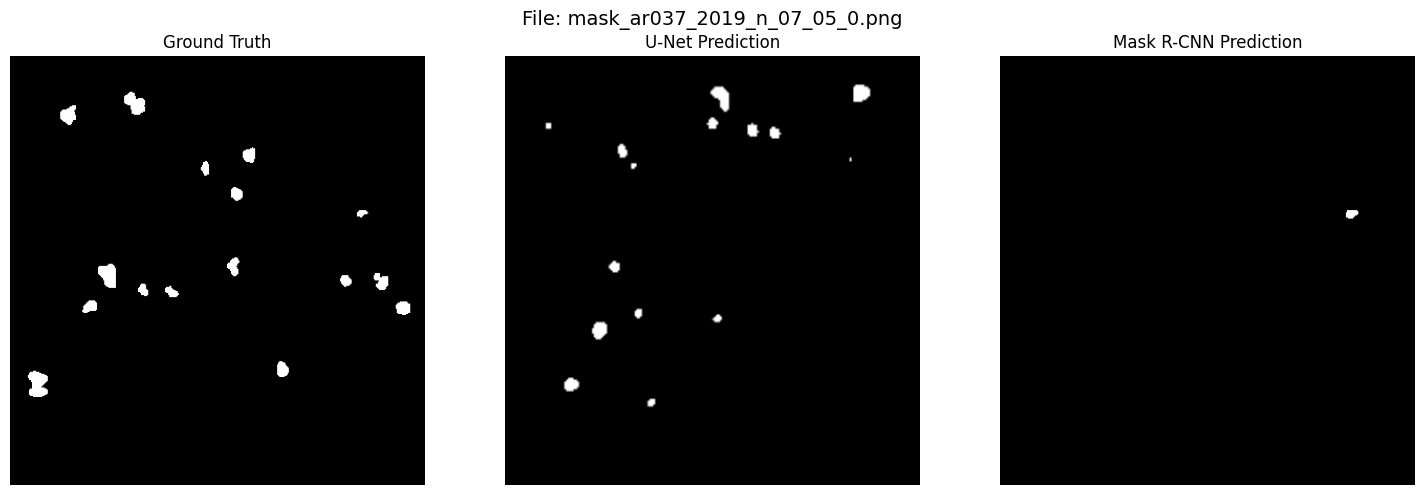

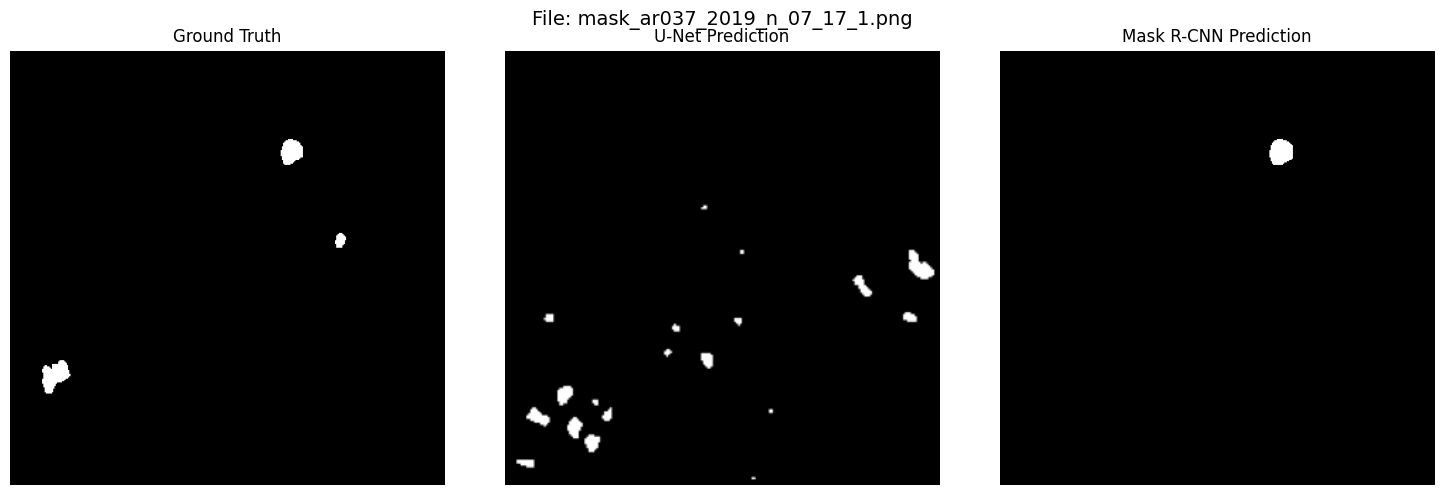

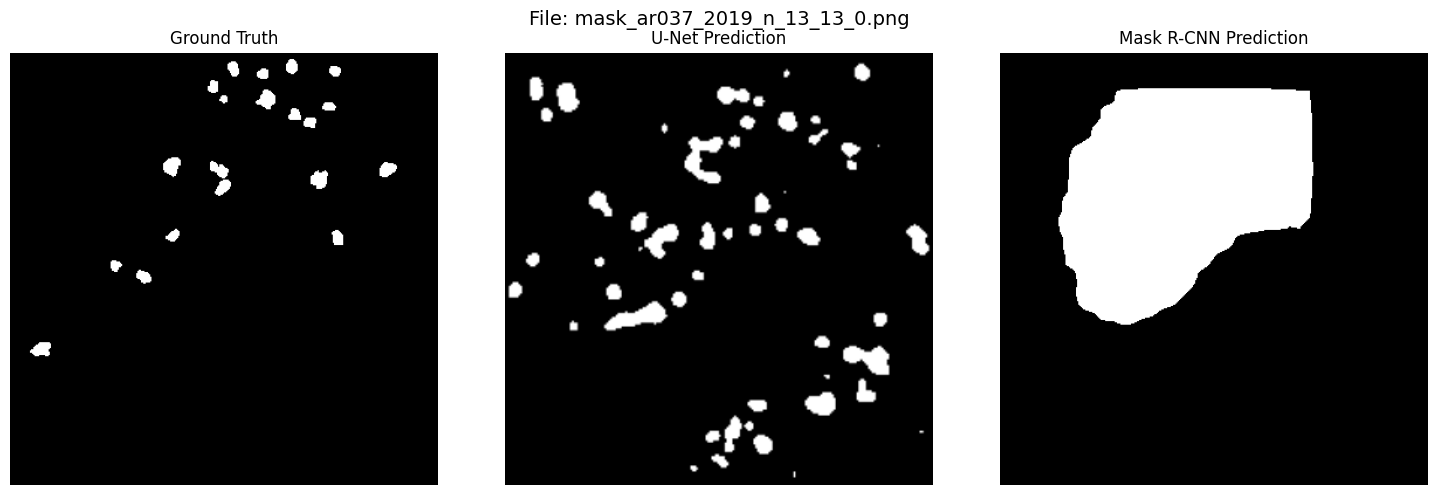

                        filename  U-Net Dice  U-Net IoU  Mask R-CNN Dice  \
0  mask_ar037_2019_n_07_05_0.png    0.001526   0.000763         0.040593   
1  mask_ar037_2019_n_07_17_1.png    0.000000   0.000000         0.535948   
2  mask_ar037_2019_n_13_13_0.png    0.053864   0.027677         0.072150   
3  mask_ar039_2019_n_05_10_0.png    0.044838   0.022933         0.451759   
4  mask_ar039_2019_n_09_09_0.png    0.008261   0.004148         0.273530   

   Mask R-CNN IoU  
0        0.020717  
1        0.366071  
2        0.037425  
3        0.291789  
4        0.158433  

✅ Global Averages:
U-Net Dice         0.030293
U-Net IoU          0.015580
Mask R-CNN Dice    0.215532
Mask R-CNN IoU     0.137619
dtype: float64


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import jaccard_score

# Paths
gt_folder = "/content/drive/MyDrive/USA_segmentation/masks/"
unet_folder = "/content/drive/MyDrive/USA_segmentation/unet_predicted_masks/"
maskrcnn_folder = "/content/drive/MyDrive/USA_segmentation/maskrcnn_predicted_masks/"

# File listings
gt_files = sorted(os.listdir(gt_folder))
unet_files = sorted(os.listdir(unet_folder))
maskrcnn_files = sorted(os.listdir(maskrcnn_folder))

# Build Mask R-CNN file map
maskrcnn_dict = {}
for f in maskrcnn_files:
    if "_mask_" in f:
        base_name = f.split("_mask_")[0] + ".png"
        if base_name not in maskrcnn_dict:
            maskrcnn_dict[base_name] = f

# Find common files
common_files = sorted(list(set(gt_files) & set(unet_files) & set(maskrcnn_dict.keys())))
print(f"✅ {len(common_files)} common files found")

results = []

# Loop through common files and compute metrics
for idx, fname in enumerate(common_files):
    # Load masks
    gt = cv2.imread(os.path.join(gt_folder, fname), 0)
    unet = cv2.imread(os.path.join(unet_folder, fname), 0)
    maskrcnn = cv2.imread(os.path.join(maskrcnn_folder, maskrcnn_dict[fname]), 0)

    # Resize if needed
    if unet.shape != gt.shape:
        unet = cv2.resize(unet, (gt.shape[1], gt.shape[0]))
    if maskrcnn.shape != gt.shape:
        maskrcnn = cv2.resize(maskrcnn, (gt.shape[1], gt.shape[0]))

    # Binarize
    gt_bin = (gt > 127).astype(np.uint8).flatten()
    unet_bin = (unet > 127).astype(np.uint8).flatten()
    maskrcnn_bin = (maskrcnn > 127).astype(np.uint8).flatten()

    # Metrics
    unet_dice = 2 * np.sum(gt_bin * unet_bin) / (np.sum(gt_bin) + np.sum(unet_bin) + 1e-6)
    unet_iou = jaccard_score(gt_bin, unet_bin)

    maskrcnn_dice = 2 * np.sum(gt_bin * maskrcnn_bin) / (np.sum(gt_bin) + np.sum(maskrcnn_bin) + 1e-6)
    maskrcnn_iou = jaccard_score(gt_bin, maskrcnn_bin)

    results.append({
        "filename": fname,
        "U-Net Dice": unet_dice,
        "U-Net IoU": unet_iou,
        "Mask R-CNN Dice": maskrcnn_dice,
        "Mask R-CNN IoU": maskrcnn_iou,
    })

    # Only visualize first 3 samples (optional)
    if idx < 3:
        fig, axs = plt.subplots(1, 3, figsize=(15, 5))
        axs[0].imshow(gt, cmap='gray')
        axs[0].set_title("Ground Truth")
        axs[1].imshow(unet, cmap='gray')
        axs[1].set_title("U-Net Prediction")
        axs[2].imshow(maskrcnn, cmap='gray')
        axs[2].set_title("Mask R-CNN Prediction")
        for ax in axs:
            ax.axis('off')
        plt.suptitle(f"File: {fname}", fontsize=14)
        plt.tight_layout()
        plt.show()

# Show metrics summary
df = pd.DataFrame(results)
print(df.head())
print("\n✅ Global Averages:")
print(df.mean(numeric_only=True))



* Overlay predictions on the original RGB image.

* Save these visualizations to disk.

* Compare results on more samples or all samples in a grid.


✅ 14 common files found


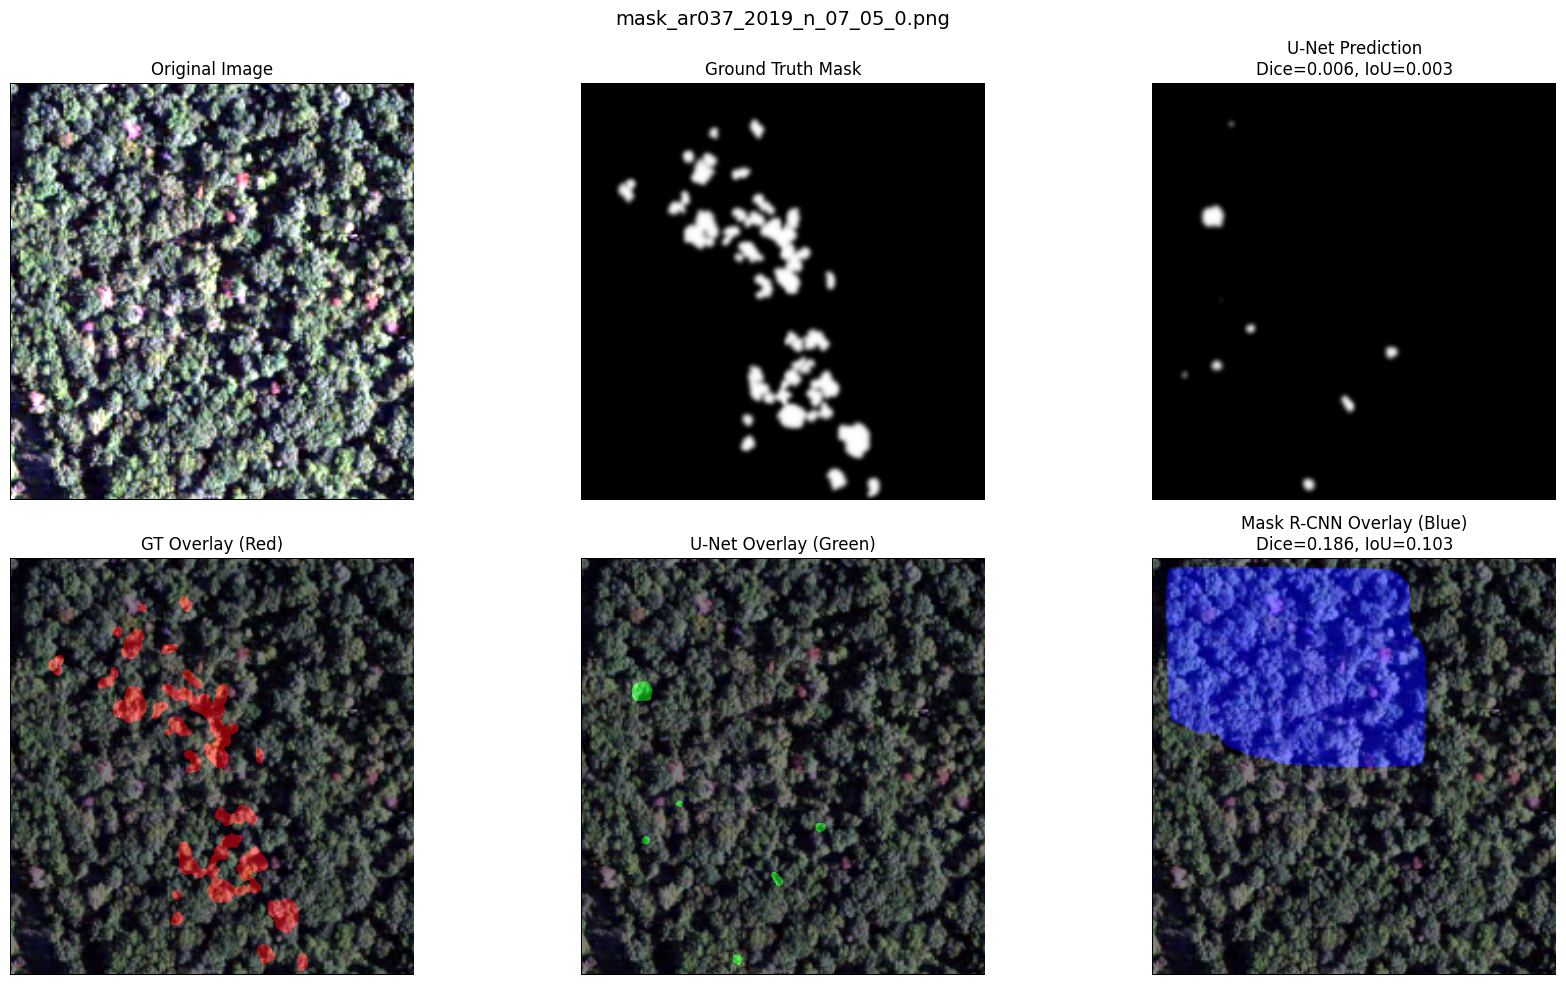

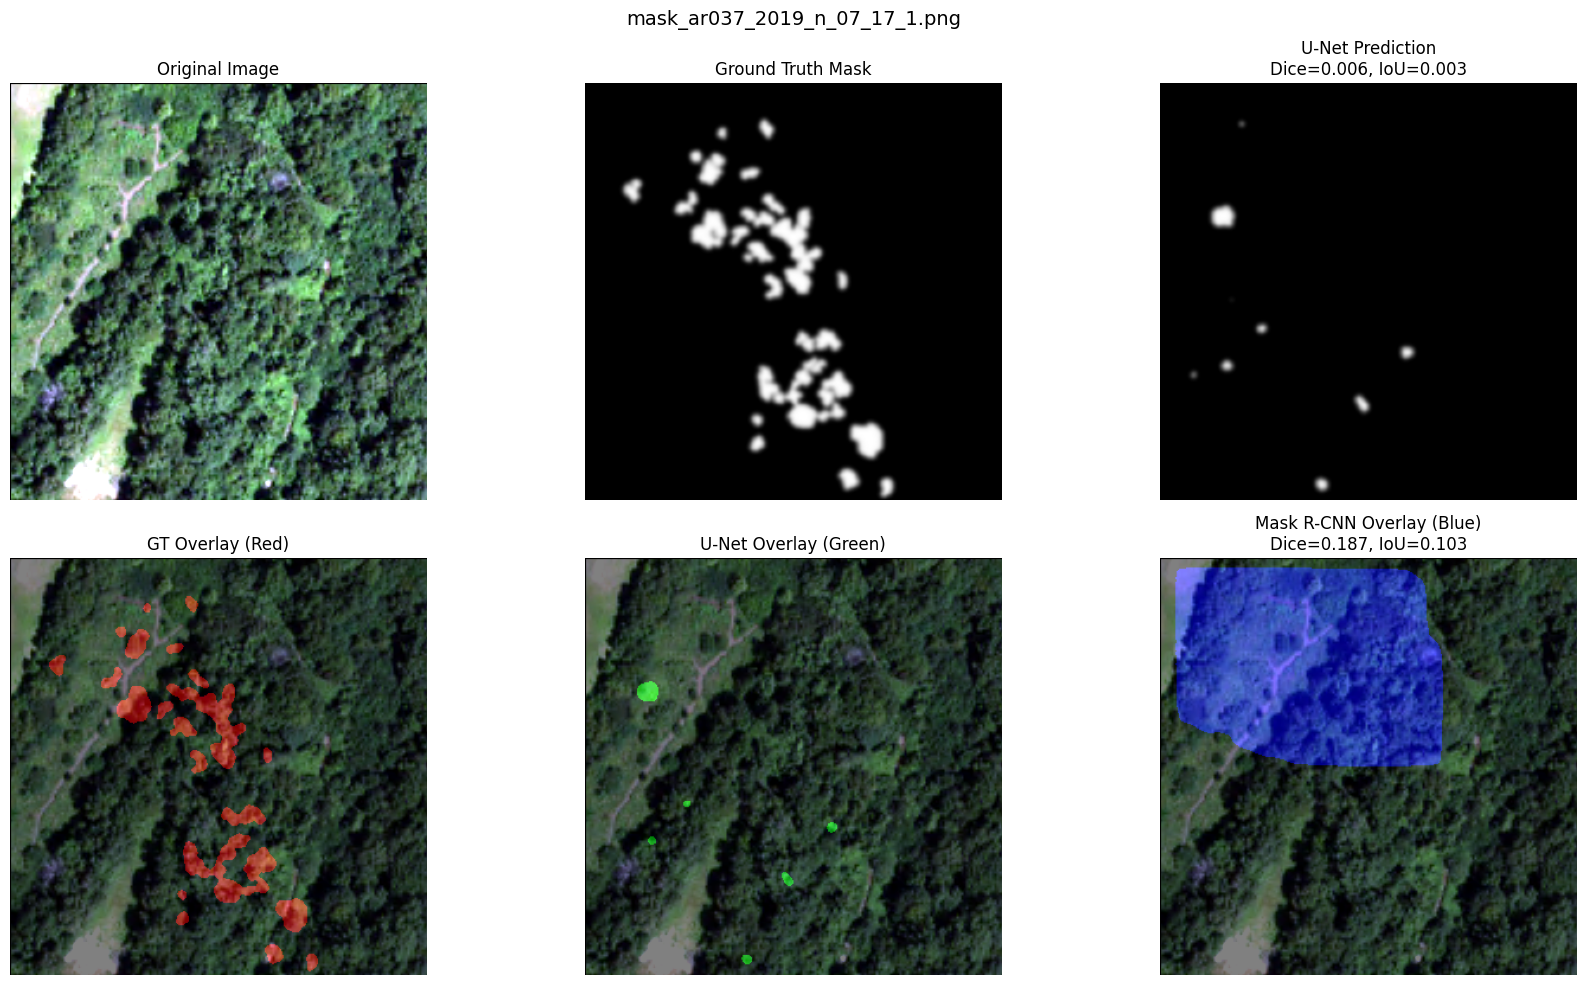

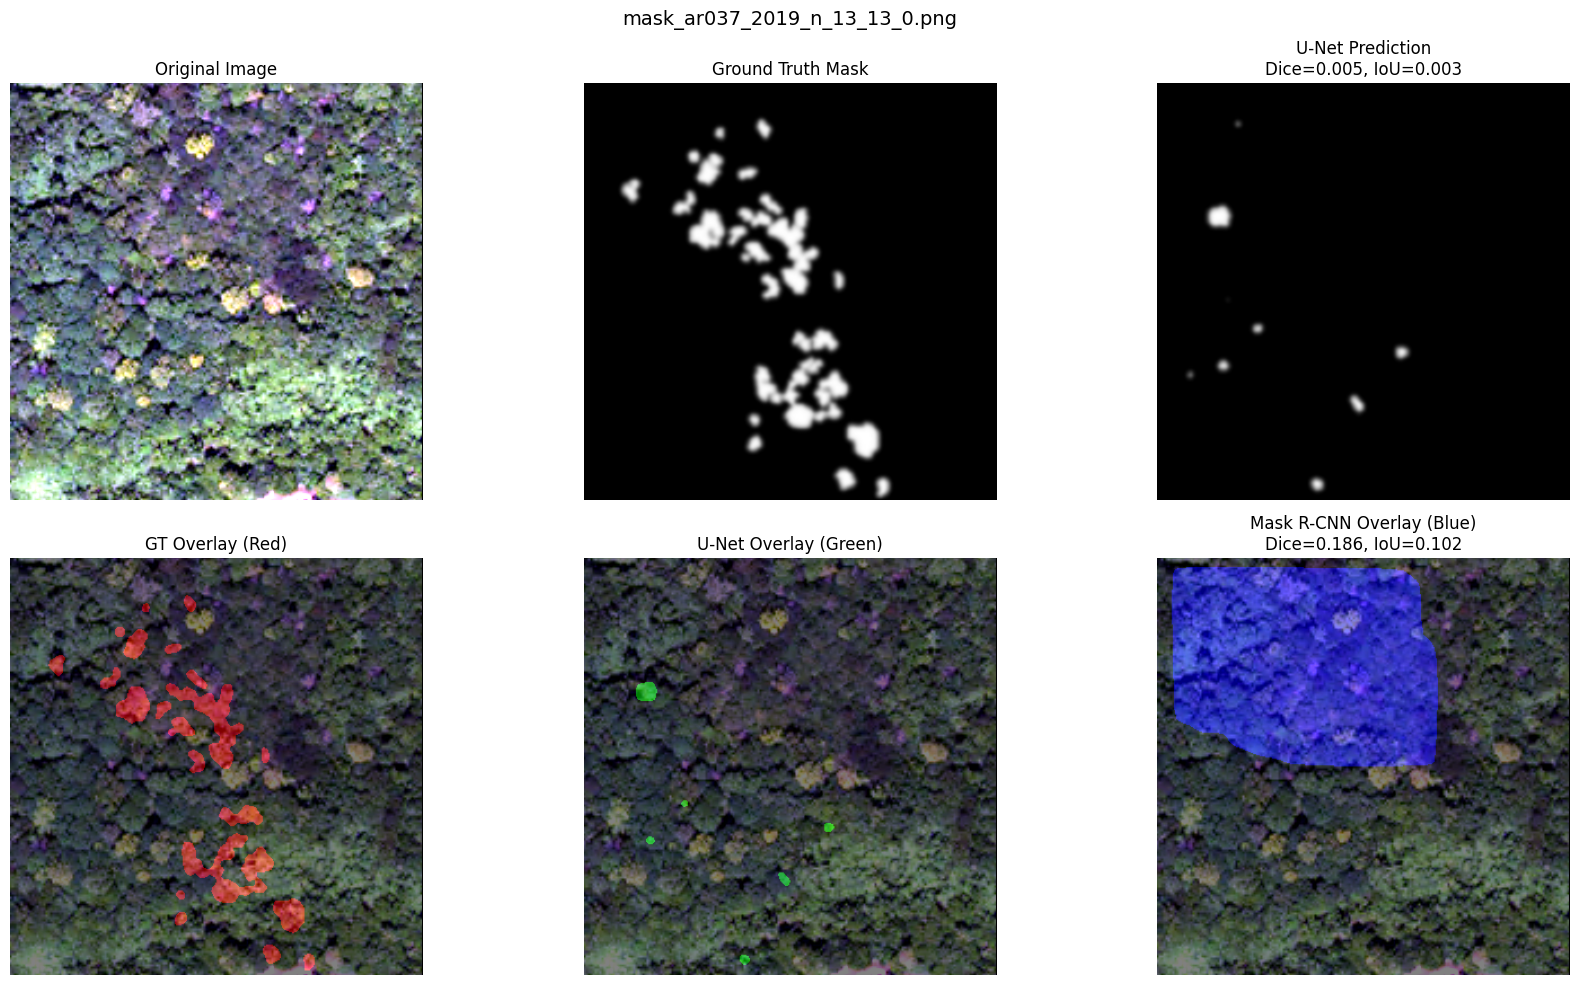

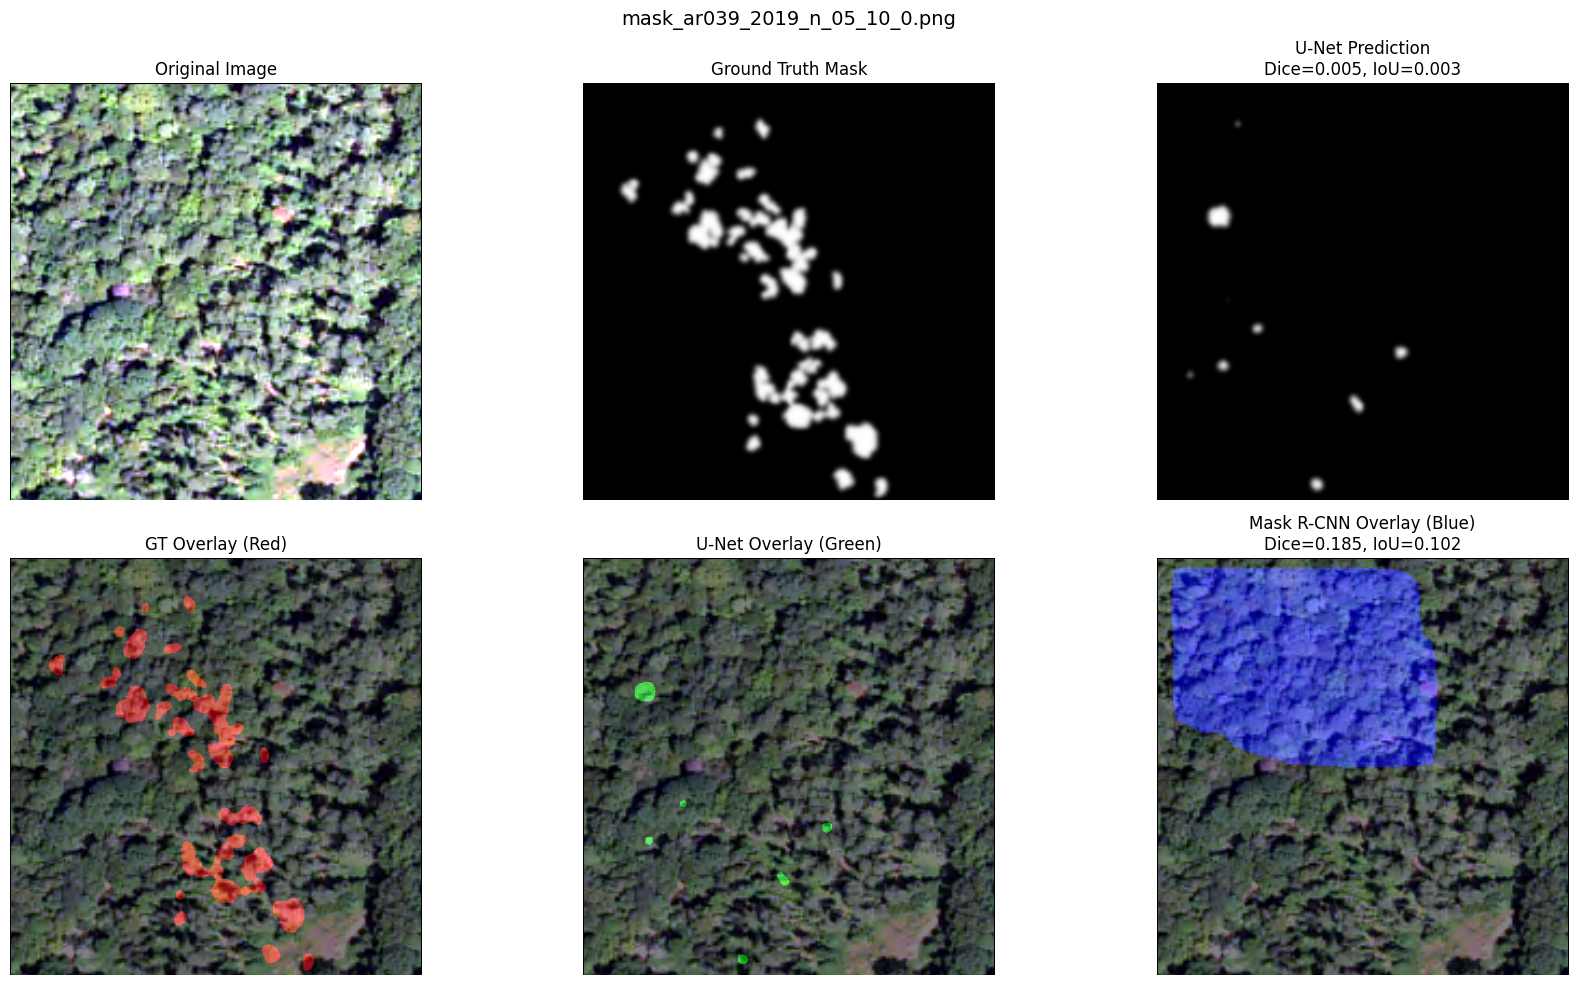

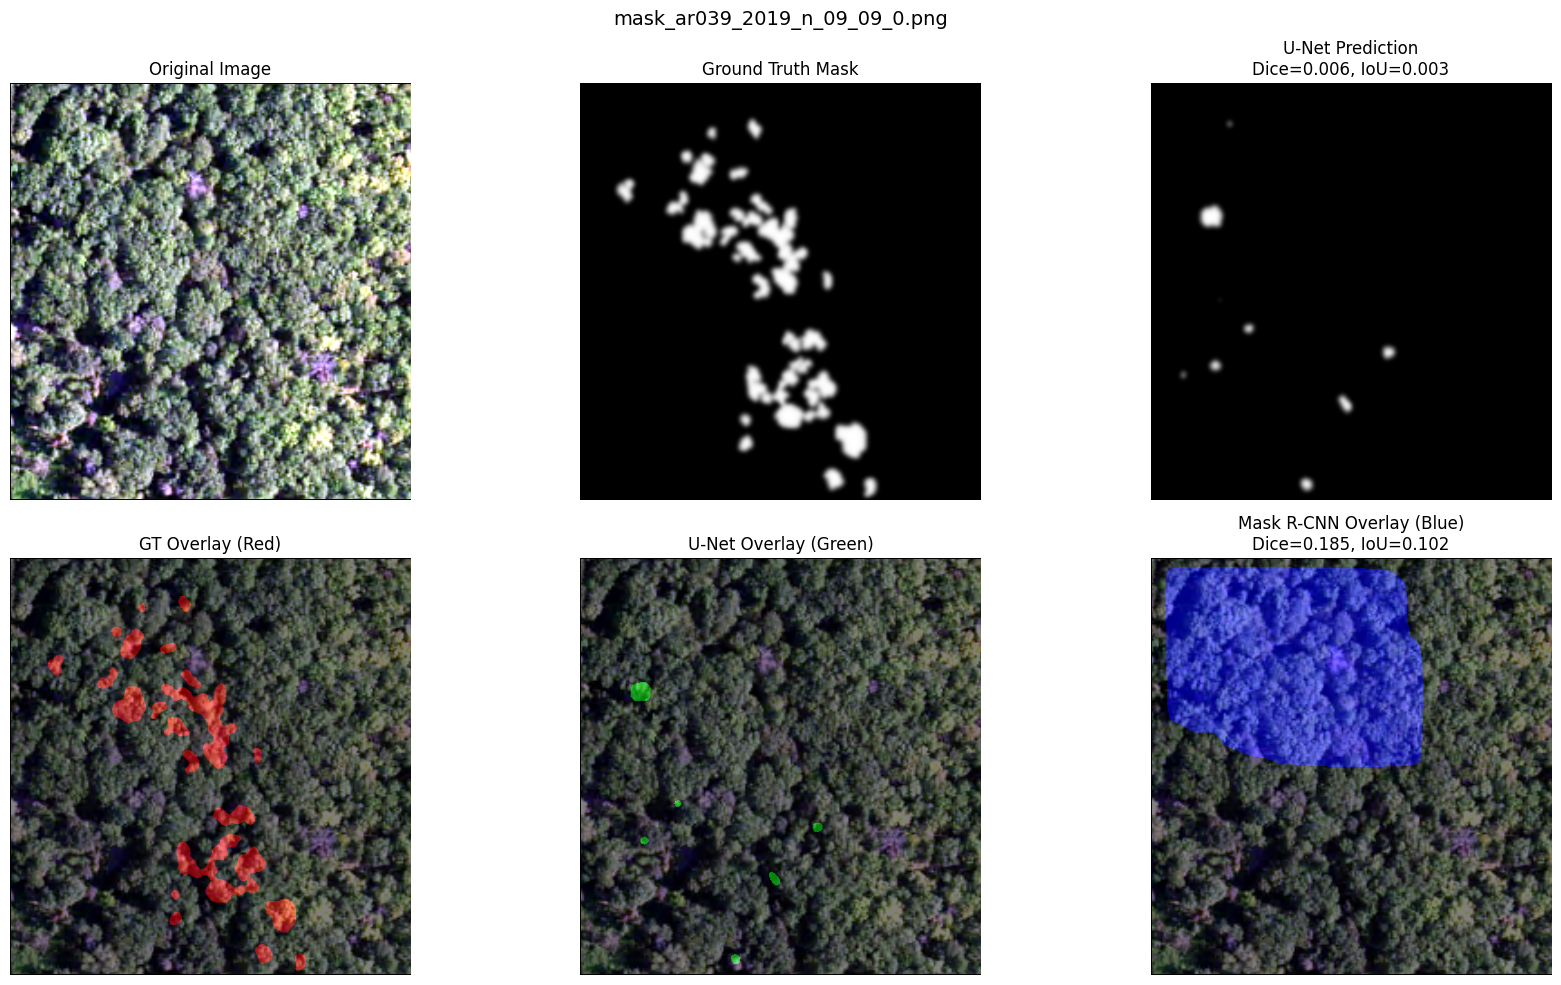

                        filename  U-Net Dice  U-Net IoU  Mask R-CNN Dice  \
0  mask_ar037_2019_n_07_05_0.png    0.006028   0.003023         0.186398   
1  mask_ar037_2019_n_07_17_1.png    0.005838   0.002927         0.186858   
2  mask_ar037_2019_n_13_13_0.png    0.005132   0.002573         0.185687   
3  mask_ar039_2019_n_05_10_0.png    0.005355   0.002685         0.185477   
4  mask_ar039_2019_n_09_09_0.png    0.005610   0.002813         0.184808   

   Mask R-CNN IoU  
0        0.102778  
1        0.103058  
2        0.102346  
3        0.102218  
4        0.101812  

✅ Global Averages:
U-Net Dice         0.005088
U-Net IoU          0.002550
Mask R-CNN Dice    0.184256
Mask R-CNN IoU     0.101478
dtype: float64


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import jaccard_score
from PIL import Image

# %matplotlib inline  # Uncomment if using Jupyter/Colab

# Paths
image_folder = "/content/drive/MyDrive/USA_segmentation/RGB_images"
gt_folder = "/content/drive/MyDrive/USA_segmentation/masks/"
unet_folder = "/content/drive/MyDrive/USA_segmentation/unet_predicted_masks/"
maskrcnn_folder = "/content/drive/MyDrive/USA_segmentation/maskrcnn_predicted_masks/"
output_folder = "/content/drive/MyDrive/USA_segmentation/visualizations"



# File listings
gt_files = sorted(os.listdir(gt_folder))
unet_files = sorted(os.listdir(unet_folder))
maskrcnn_files = sorted(os.listdir(maskrcnn_folder))

# Build Mask R-CNN file map
maskrcnn_dict = {}
for f in maskrcnn_files:
    if "_mask_" in f:
        base_name = f.split("_mask_")[0] + ".png"
        if base_name not in maskrcnn_dict:
            maskrcnn_dict[base_name] = f

# Find common files
common_files = sorted(list(set(gt_files) & set(unet_files) & set(maskrcnn_dict.keys())))
print(f"✅ {len(common_files)} common files found")

results = []

# Loop through common files
for idx, fname in enumerate(common_files):
    # Try to find image with 'RGB_' prefix
    base_name = fname.replace("mask_", "").replace(".png", "")
    rgb_name = f"RGB_{base_name}.png"
    image_path = os.path.join(image_folder, rgb_name)

    if not os.path.exists(image_path):
        print(f"⚠️ Skipped: RGB image not found for {rgb_name}")
        continue




    rgb = cv2.imread(image_path)
    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    # Resize if needed
    gt = cv2.resize(gt, (rgb.shape[1], rgb.shape[0]))
    unet = cv2.resize(unet, (rgb.shape[1], rgb.shape[0]))
    maskrcnn = cv2.resize(maskrcnn, (rgb.shape[1], rgb.shape[0]))

    # Binarize
    gt_bin = (gt > 127).astype(np.uint8).flatten()
    unet_bin = (unet > 127).astype(np.uint8).flatten()
    maskrcnn_bin = (maskrcnn > 127).astype(np.uint8).flatten()

    # Metrics
    unet_dice = 2 * np.sum(gt_bin * unet_bin) / (np.sum(gt_bin) + np.sum(unet_bin) + 1e-6)
    unet_iou = jaccard_score(gt_bin, unet_bin)

    maskrcnn_dice = 2 * np.sum(gt_bin * maskrcnn_bin) / (np.sum(gt_bin) + np.sum(maskrcnn_bin) + 1e-6)
    maskrcnn_iou = jaccard_score(gt_bin, maskrcnn_bin)

    results.append({
        "filename": fname,
        "U-Net Dice": unet_dice,
        "U-Net IoU": unet_iou,
        "Mask R-CNN Dice": maskrcnn_dice,
        "Mask R-CNN IoU": maskrcnn_iou,
    })

    # Overlay masks on image (for first few samples or all)
    if idx < 5:
        fig, axs = plt.subplots(2, 3, figsize=(18, 10))

        axs[0, 0].imshow(rgb)
        axs[0, 0].set_title("Original Image")
        axs[0, 1].imshow(gt, cmap='gray')
        axs[0, 1].set_title("Ground Truth Mask")
        axs[0, 2].imshow(unet, cmap='gray')
        axs[0, 2].set_title(f"U-Net Prediction\nDice={unet_dice:.3f}, IoU={unet_iou:.3f}")

        # Overlays
        def overlay(image, mask, color=(0, 255, 0), alpha=0.5):
            overlayed = image.copy()
            colored_mask = np.zeros_like(image)
            colored_mask[mask > 127] = color
            return cv2.addWeighted(overlayed, 1 - alpha, colored_mask, alpha, 0)

        axs[1, 0].imshow(overlay(rgb, gt, (255, 0, 0)))  # Red = GT
        axs[1, 0].set_title("GT Overlay (Red)")

        axs[1, 1].imshow(overlay(rgb, unet, (0, 255, 0)))  # Green = U-Net
        axs[1, 1].set_title("U-Net Overlay (Green)")

        axs[1, 2].imshow(overlay(rgb, maskrcnn, (0, 0, 255)))  # Blue = Mask R-CNN
        axs[1, 2].set_title(f"Mask R-CNN Overlay (Blue)\nDice={maskrcnn_dice:.3f}, IoU={maskrcnn_iou:.3f}")

        for ax in axs.flat:
            ax.axis('off')
        plt.suptitle(fname, fontsize=14)
        plt.tight_layout()

        # Save figure
        save_path = os.path.join(output_folder, fname.replace('.png', '_comparison.png'))
        plt.savefig(save_path, dpi=200)
        plt.show()

# Show metrics summary
df = pd.DataFrame(results)
print(df.head())
print("\n✅ Global Averages:")
print(df.mean(numeric_only=True))


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import jaccard_score

# Paths
image_folder = "/content/drive/MyDrive/USA_segmentation/RGB_images"
gt_folder = "/content/drive/MyDrive/USA_segmentation/masks/"
unet_folder = "/content/drive/MyDrive/USA_segmentation/unet_predicted_masks/"
maskrcnn_folder = "/content/drive/MyDrive/USA_segmentation/maskrcnn_predicted_masks/"
output_folder = "/content/drive/MyDrive/USA_segmentation/visualizations"

# Create folder to save visualizations
os.makedirs(output_folder, exist_ok=True)

# File listings
gt_files = sorted(os.listdir(gt_folder))
unet_files = sorted(os.listdir(unet_folder))
maskrcnn_files = sorted(os.listdir(maskrcnn_folder))

# Map Mask R-CNN
maskrcnn_dict = {}
for f in maskrcnn_files:
    if "_mask_" in f:
        base_name = f.split("_mask_")[0] + ".png"
        if base_name not in maskrcnn_dict:
            maskrcnn_dict[base_name] = f

# Find common files
common_files = sorted(list(set(gt_files) & set(unet_files) & set(maskrcnn_dict.keys())))
print(f"✅ {len(common_files)} common files found")

results = []

def overlay(image, mask, color=(0, 255, 0), alpha=0.5):
    """Overlay a binary mask on an image."""
    overlayed = image.copy()
    colored_mask = np.zeros_like(image)
    colored_mask[mask > 127] = color
    return cv2.addWeighted(overlayed, 1 - alpha, colored_mask, alpha, 0)

# Loop through files
for idx, fname in enumerate(common_files):
    base_name = fname.replace("mask_", "").replace(".png", "")
    rgb_name = f"RGB_{base_name}.png"
    image_path = os.path.join(image_folder, rgb_name)

    if not os.path.exists(image_path):
        print(f"⚠️ Skipped: RGB image not found for {rgb_name}")
        continue

    # Load data
    gt = cv2.imread(os.path.join(gt_folder, fname), 0)
    unet = cv2.imread(os.path.join(unet_folder, fname), 0)
    maskrcnn = cv2.imread(os.path.join(maskrcnn_folder, maskrcnn_dict[fname]), 0)
    rgb = cv2.imread(image_path)
    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    # Resize masks
    gt = cv2.resize(gt, (rgb.shape[1], rgb.shape[0]))
    unet = cv2.resize(unet, (rgb.shape[1], rgb.shape[0]))
    maskrcnn = cv2.resize(maskrcnn, (rgb.shape[1], rgb.shape[0]))

    # Binarize
    gt_bin = (gt > 127).astype(np.uint8).flatten()
    unet_bin = (unet > 127).astype(np.uint8).flatten()
    maskrcnn_bin = (maskrcnn > 127).astype(np.uint8).flatten()

    # Metrics
    unet_dice = 2 * np.sum(gt_bin * unet_bin) / (np.sum(gt_bin) + np.sum(unet_bin) + 1e-6)
    unet_iou = jaccard_score(gt_bin, unet_bin)

    maskrcnn_dice = 2 * np.sum(gt_bin * maskrcnn_bin) / (np.sum(gt_bin) + np.sum(maskrcnn_bin) + 1e-6)
    maskrcnn_iou = jaccard_score(gt_bin, maskrcnn_bin)

    results.append({
        "filename": fname,
        "U-Net Dice": unet_dice,
        "U-Net IoU": unet_iou,
        "Mask R-CNN Dice": maskrcnn_dice,
        "Mask R-CNN IoU": maskrcnn_iou,
    })

    # Create figure
    fig, axs = plt.subplots(2, 3, figsize=(18, 10))

    axs[0, 0].imshow(rgb)
    axs[0, 0].set_title("Original Image")

    axs[0, 1].imshow(gt, cmap='gray')
    axs[0, 1].set_title("Ground Truth")

    axs[0, 2].imshow(unet, cmap='gray')
    axs[0, 2].set_title(f"U-Net\nDice: {unet_dice:.3f}, IoU: {unet_iou:.3f}")

    axs[1, 0].imshow(overlay(rgb, gt, (255, 0, 0)))  # Red
    axs[1, 0].set_title("GT Overlay (Red)")

    axs[1, 1].imshow(overlay(rgb, unet, (0, 255, 0)))  # Green
    axs[1, 1].set_title("U-Net Overlay (Green)")

    axs[1, 2].imshow(overlay(rgb, maskrcnn, (0, 0, 255)))  # Blue
    axs[1, 2].set_title(f"Mask R-CNN Overlay (Blue)\nDice: {maskrcnn_dice:.3f}, IoU: {maskrcnn_iou:.3f}")

    for ax in axs.flat:
        ax.axis('off')

    plt.tight_layout()
    fig.suptitle(base_name, fontsize=16)

    # ✅ Save figure
    save_path = os.path.join(output_folder, base_name + "_comparison.png")
    plt.savefig(save_path, dpi=200)
    plt.close()

    print(f"✅ Saved: {save_path}")

# Export metrics
df = pd.DataFrame(results)
print("\n🔍 Sample Metrics:")
print(df.head())

print("\n✅ Global Averages:")
print(df.mean(numeric_only=True))

# Save metrics CSV
df.to_csv(os.path.join(output_folder, "segmentation_metrics.csv"), index=False)
print("📄 Saved metrics to CSV.")


✅ 14 common files found
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar037_2019_n_07_05_0_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar037_2019_n_07_17_1_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar037_2019_n_13_13_0_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar039_2019_n_05_10_0_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar039_2019_n_09_09_0_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar039_2019_n_11_03_0_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar039_2019_n_16_19_0_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar041_2021_n_06_16_0_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar041_2021_n_14_13_0_comparison.png
✅ Saved: /content/drive/MyDrive/USA_segmentation/visualizations/ar081_2021_n

In [ ]:
df.to_csv("results_comparison.csv", index=False)


In [ ]:
!ls "/content/drive/My Drive/USA_segmentation"